# TrOCR: original versus denoised handwriting
Compare the same 10 IAM validation lines with a fixed pretrained recognizer. No training.
CER/WER use corpus edit totals divided by reference totals. Whitespace is collapsed; case and punctuation are retained. Raw text is saved unchanged. These small-sample results are illustrative, not final evaluation.

The [MIT-licensed checkpoint](https://huggingface.co/microsoft/trocr-base-handwritten) is fine-tuned on IAM English handwriting. Its mandatory RGB conversion, resizing and normalization run identically after optional preprocessing. Reserve the test split for final evaluation.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset
from huggingface_hub import HfApi
from src.load_dataset.iam import get_sample
from src.models import TrOCRRecognizer
from src.preprocessing import NonLocalMeans, PreprocessingPipeline
from src.evaluation import compare_recognition

In [2]:
CHECKPOINT = "microsoft/trocr-base-handwritten"
MODEL_REVISION = "main"  # Resolved to an immutable commit below.
DATASET_REVISION = "main"
SPLIT = "validation"
SAMPLE_INDICES = list(range(10))
DEVICE = "cpu"  # Explicit portable default; may change to cuda or mps.
GENERATION = {"max_new_tokens": 128, "num_beams": 1, "do_sample": False}
pipelines = {
    "baseline": PreprocessingPipeline(),
    "denoising_h3": PreprocessingPipeline((NonLocalMeans(h=3.0, h_color=3.0),)),
}

In [3]:
dataset_revision = HfApi().dataset_info("Teklia/IAM-line", revision=DATASET_REVISION).sha
dataset = load_dataset("Teklia/IAM-line", split=SPLIT, revision=dataset_revision)
assert len(SAMPLE_INDICES) == len(set(SAMPLE_INDICES)), "Duplicate samples"
samples = [get_sample(dataset, index) for index in SAMPLE_INDICES]
print({"split": SPLIT, "split_size": len(dataset), "columns": dataset.column_names,
       "selected": len(samples), "revision": dataset_revision})
display(pd.DataFrame([{"id": s["id"], "ground_truth": s["ground_truth"],
                       "mode": s["image"].mode, "size": s["image"].size} for s in samples]))

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


{'split': 'validation', 'split_size': 976, 'columns': ['image', 'text'], 'selected': 10, 'revision': 'fbdad97500ce54635c0d1ba306bf535cb40656cf'}


,id,ground_truth,mode,size
0,sample_0,It was a splendid interpretation of the,L,"(1273, 128)"
1,sample_1,sympathetic C O . Paul Daneman gave another,L,"(1159, 128)"
2,sample_2,"part . The rest of the cast were well chosen ,",L,"(1318, 128)"
3,sample_3,with James Maxwell making a fine job of the,L,"(1355, 128)"
4,sample_4,""" The Little Key . """,L,"(564, 128)"
5,sample_5,first-class performance last night as a,L,"(1222, 128)"
6,sample_6,wartime naval officer in the B B C's,L,"(1347, 128)"
7,sample_7,the imagination which asked the viewer to,L,"(1254, 128)"
8,sample_8,""" Britain - Blood , Sweat , and Tears ... Plus",L,"(1334, 128)"
9,sample_9,The play was no more than a figment of,L,"(1333, 128)"


In [4]:
model = TrOCRRecognizer(CHECKPOINT, revision=MODEL_REVISION, device=DEVICE,
                         generation_kwargs=GENERATION)
print({key: model.to_config()[key] for key in ("checkpoint", "revision", "device")})

W1101 12:15:57.761000 87473 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.17k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

{'checkpoint': 'microsoft/trocr-base-handwritten', 'revision': 'eaacaf452b06415df8f10bb6fad3a4c11e609406', 'device': 'cpu'}


In [5]:
rows, summaries = compare_recognition(samples, model, pipelines)
predictions = pd.DataFrame(rows)
summary = pd.DataFrame(summaries).set_index("configuration")
summary["cer_change_from_baseline"] = summary["cer"] - summary.loc["baseline", "cer"]
summary["wer_change_from_baseline"] = summary["wer"] - summary.loc["baseline", "wer"]
display(summary)
display(predictions[["configuration", "sample_id", "ground_truth", "prediction", "cer", "wer"]])

baseline: 1/10
baseline: 2/10
baseline: 3/10
baseline: 4/10
baseline: 5/10
baseline: 6/10
baseline: 7/10
baseline: 8/10
baseline: 9/10
baseline: 10/10
denoising_h3: 1/10
denoising_h3: 2/10
denoising_h3: 3/10
denoising_h3: 4/10
denoising_h3: 5/10
denoising_h3: 6/10
denoising_h3: 7/10
denoising_h3: 8/10
denoising_h3: 9/10
denoising_h3: 10/10


,sample_count,cer,wer,inference_seconds,cer_change_from_baseline,wer_change_from_baseline
configuration,,,,,,
baseline,10,0.030691,0.121951,7.584758,0.0,0.0
denoising_h3,10,0.030691,0.121951,7.527760,0.0,0.0


,configuration,sample_id,ground_truth,prediction,cer,wer
0,baseline,sample_0,It was a splendid interpretation of the,It was a splendid interpretation of that,0.051282,0.142857
1,baseline,sample_1,sympathetic C O . Paul Daneman gave another,sympathetic CO . Paul Daneman gave another,0.023256,0.250000
2,baseline,sample_2,"part . The rest of the cast were well chosen ,","part . The rest of the cast were well chosen ,",0.000000,0.000000
3,baseline,sample_3,with James Maxwell making a fine job of the,with James Maxwell making a fine job of the,0.000000,0.000000
4,baseline,sample_4,""" The Little Key . """,""" The Little Key . """,0.000000,0.000000
5,baseline,sample_5,first-class performance last night as a,first-class performance last night as a,0.000000,0.000000
6,baseline,sample_6,wartime naval officer in the B B C's,wartime naval officer in the BBC's,0.055556,0.375000
7,baseline,sample_7,the imagination which asked the viewer to,the imagination which asked the viewer to,0.000000,0.000000
8,baseline,sample_8,""" Britain - Blood , Sweat , and Tears ... Plus","' Britain - Blood ' , Tweet , and Tears ... . ...",0.152174,0.363636
9,baseline,sample_9,The play was no more than a figment of,The play was no more than a figment of,0.000000,0.000000


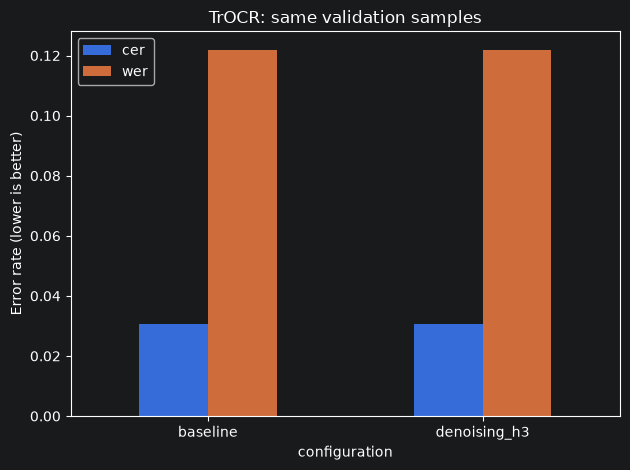

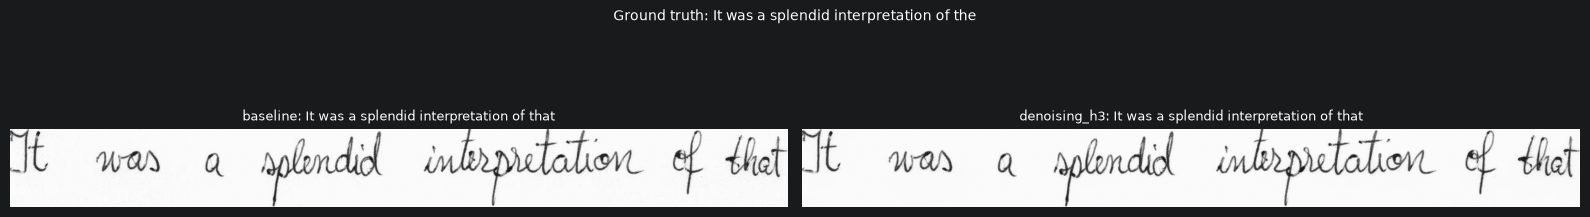

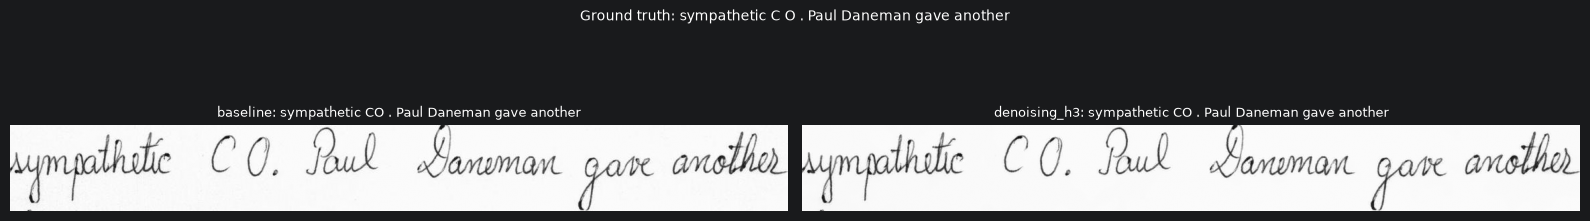

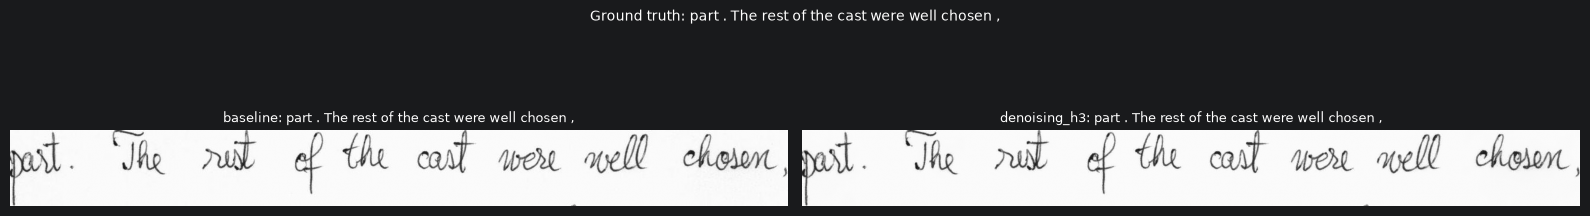

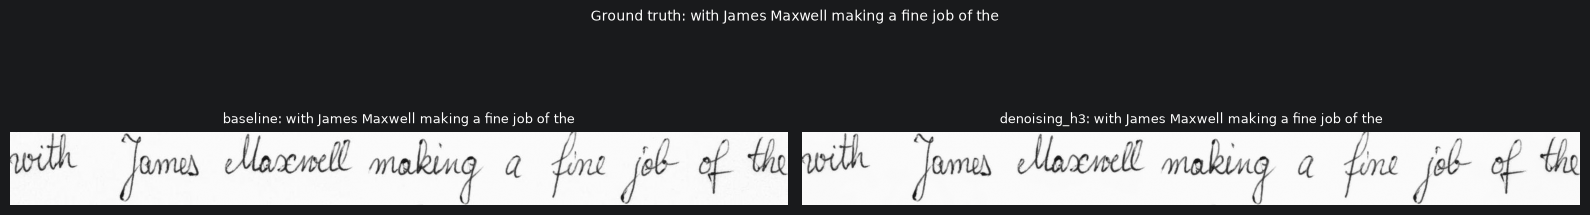

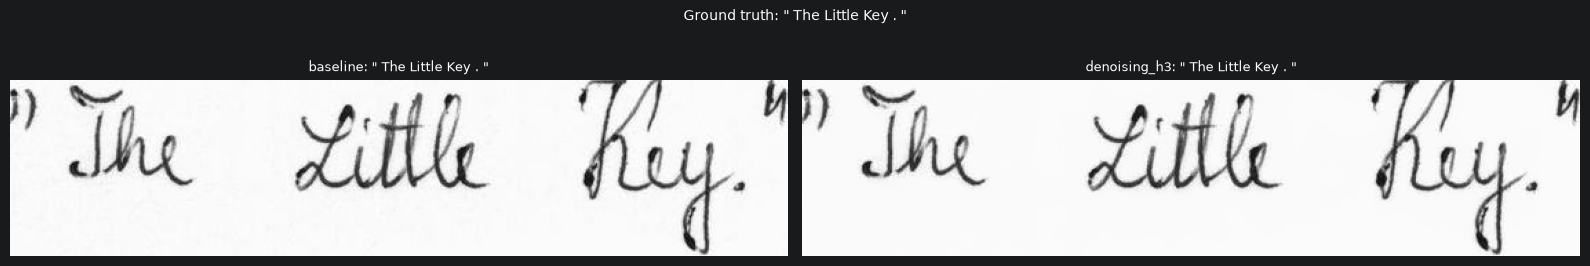

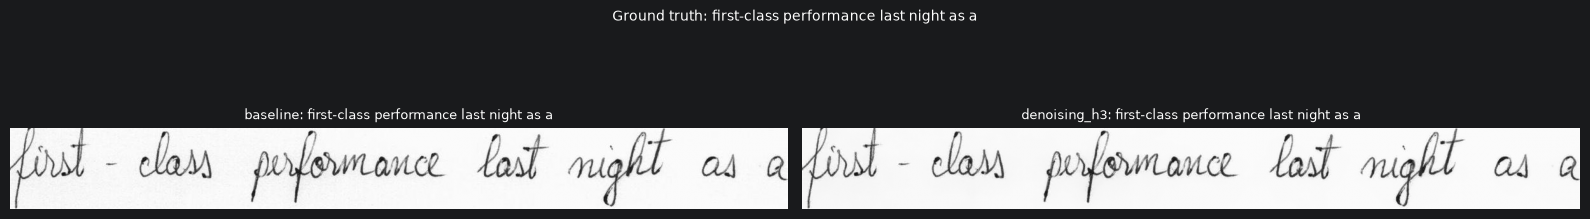

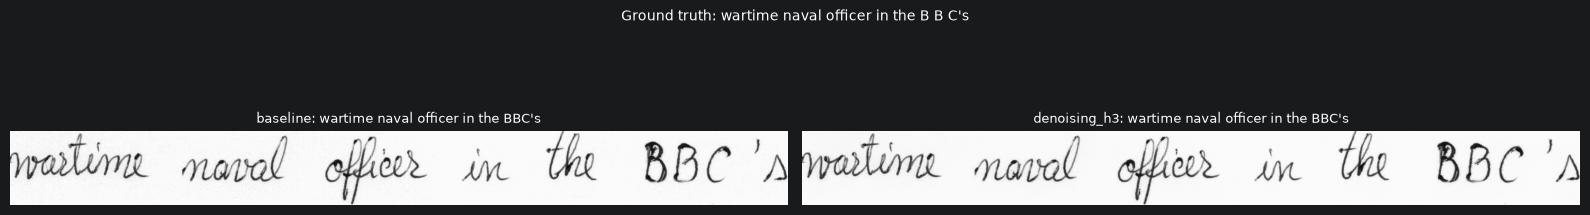

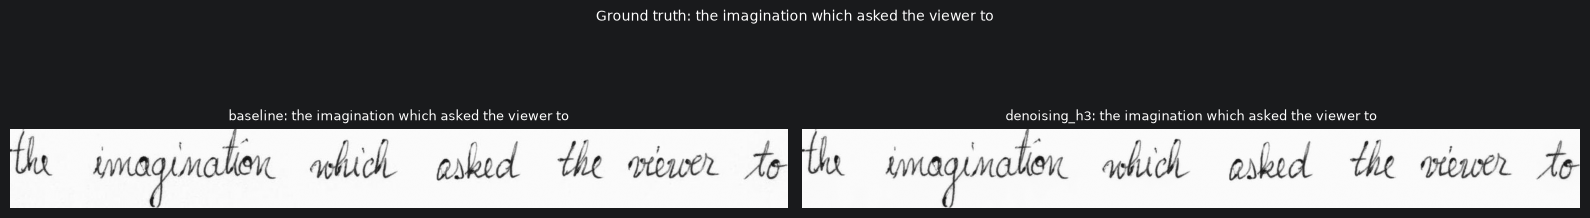

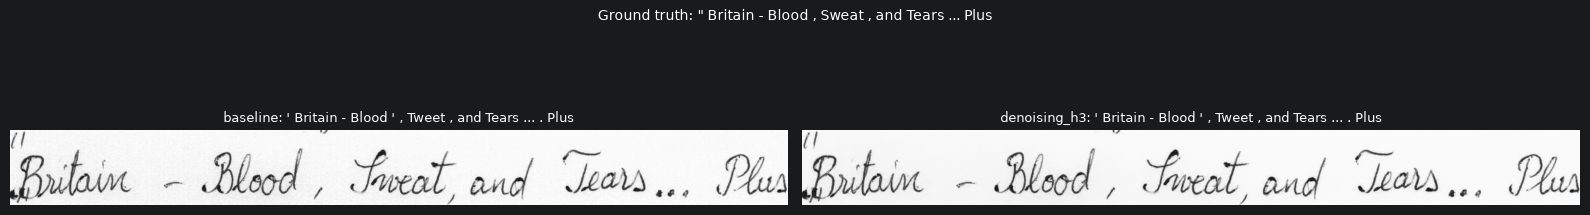

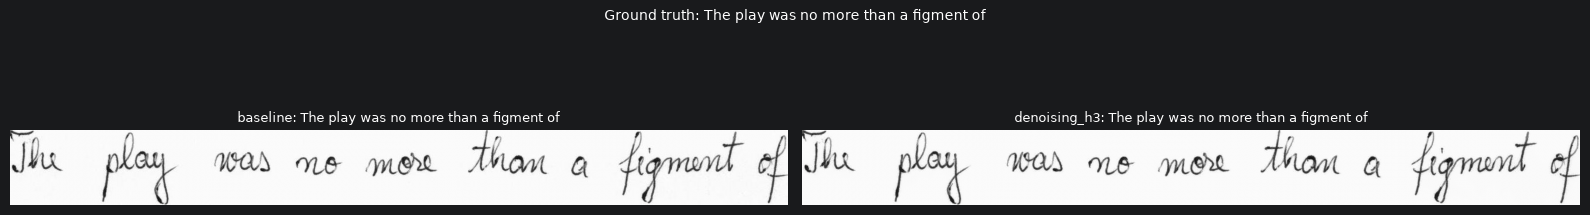

In [6]:
summary[["cer", "wer"]].plot.bar(rot=0, ylabel="Error rate (lower is better)",
                                title="TrOCR: same validation samples")
plt.tight_layout()
plt.show()
for sample in samples:
    fig, axes = plt.subplots(1, len(pipelines), figsize=(16, 3), squeeze=False)
    for axis, (name, pipeline) in zip(axes[0], pipelines.items()):
        prediction = predictions.loc[(predictions.sample_id == sample["id"]) &
                                     (predictions.configuration == name), "prediction"].iloc[0]
        axis.imshow(pipeline(sample["image"]), cmap="gray")
        axis.set_title(name + ": " + prediction, wrap=True, fontsize=9)
        axis.axis("off")
    fig.suptitle("Ground truth: " + sample["ground_truth"], wrap=True, fontsize=10)
    plt.tight_layout()
    plt.show()

In [7]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
output = ROOT / "results" / ("trocr_" + run_id)
output.mkdir(parents=True, exist_ok=False)
metadata = {
    "experiment_id": run_id, "dataset": "Teklia/IAM-line", "split": SPLIT,
    "dataset_revision": dataset_revision, "dataset_fingerprint": dataset._fingerprint,
    "sample_indices": SAMPLE_INDICES, "model": model.to_config(),
    "pipelines": {name: pipe.to_config() for name, pipe in pipelines.items()},
    "normalization": "collapse whitespace; strip edges; retain case and punctuation",
    "python": platform.python_version(),
    "versions": {name: version(name) for name in ["torch", "transformers", "datasets",
        "huggingface-hub", "jiwer", "Pillow", "numpy", "opencv-python-headless", "pandas"]},
    "timing": "wall seconds; excludes model loading; includes mandatory input transforms",
}
predictions.to_csv(output / "predictions.csv", index=False)
summary.to_csv(output / "summary.csv")
(output / "metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved:", output)

Saved: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/trocr_20261101T171651853840Z
